# ICS 3202 Artificial Intelligence: Semester Project
## Base model: Naive Bayes transaction categoriser for Akiba

Akiba is a personal finance app for university students. This notebook builds the model that reads an M-Pesa transaction (a short description and an amount) and predicts one of nine expense categories: Food, Rent, Transport, Academic, Airtime & Data, Entertainment, Health, Personal Care and Other.

1. Data exploration
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Model training and validation

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether the notebook is run from the notebooks/ folder or from the repository root
ROOT = Path("..") if Path("../data/train.csv").exists() else Path(".")
sys.path.insert(0, str(ROOT / "scripts"))

# Cleaning functions and category amount limits used for data-quality checks
from features import clean, amount_bucket, to_document, vectorizer_kwargs
from generate import AMOUNT_RANGES

# 1. Data exploration

## Data source and preparation

We obtained the dataset analysed in this notebook from Kaggle: **[add dataset name and link]**. The analysis below uses the 5,587 records in that dataset. The reported summaries and model results describe this Kaggle dataset.


In [2]:
df = pd.read_csv(ROOT / "data" / "train.csv")

print("Rows, columns:", df.shape)
print()
print(df.dtypes)
df.head(8)

Rows, columns: (5587, 4)

description      str
amount         int64
category         str
keyword          str
dtype: object


,description,amount,category,keyword
0,faiba cbd,340,Airtime & Data,faiba
1,buy goods grocery,115,Food,grocery
2,customer transfer to pharmacy,2612,Health,pharmacy
3,merchant payment to cash thika road,65,Other,cash
4,pay bill online to pizza,171,Food,pizza
5,pay bill online to faras,611,Transport,faras
6,gym branch westlands,2110,Personal Care,gym
7,customer transfer to m shwari,59,Other,m shwari


- `description`: the M-Pesa transaction text
- `amount`: the amount in KES
- `category`: the label we want to predict
- `keyword`: the merchant or transaction keyword included in the dataset. It is kept for checking only; the model never uses it.


In [3]:
# Rows and distinct merchant keywords in each category
per_category = df.groupby("category").agg(rows=("category", "size"), keywords=("keyword", "nunique"))
per_category["rows_per_keyword"] = (per_category["rows"] / per_category["keywords"]).round(1)

print("Distinct merchant keywords:", df["keyword"].nunique())
per_category.sort_values("keywords")

Distinct merchant keywords: 457


,rows,keywords,rows_per_keyword
category,,,
Airtime & Data,602,43,14.0
Rent,630,45,14.0
Health,611,47,13.0
Personal Care,637,49,13.0
Other,612,51,12.0
Entertainment,636,53,12.0
Food,616,56,11.0
Academic,616,56,11.0
Transport,627,57,11.0


In [4]:
# Smallest, middle (median) and largest amount in each category, in KES
df.groupby("category")["amount"].agg(["min", "median", "max"]).sort_values("median")

,min,median,max
category,,,
Airtime & Data,10,172.5,2987
Transport,50,411.0,2964
Food,50,503.0,4991
Other,50,567.0,9831
Personal Care,100,662.0,4979
Entertainment,100,748.5,4989
Health,100,1000.0,9912
Academic,20,1255.5,58090
Rent,307,3468.5,44911


The dataset has 5,587 rows and 4 columns. Each category contains between 602 and 637 rows and is associated with 43 to 57 merchant keywords. Amounts range from KES 10 to about KES 58,000, and Rent and Academic have the highest typical amounts.


# 2. Data cleaning

We worked through the seven data cleaning steps from the course notes. For each step we either fixed the problem or checked that it was not present.

## Step 1: Duplicates

In [5]:
# Exact duplicates: same description, amount and category
print("Exact duplicate rows:", df.duplicated(["description", "amount", "category"]).sum())

# Descriptions that appear more than once, and whether any of them has two different categories
print("Repeated descriptions:", df["description"].duplicated().sum())
print("Repeated descriptions with conflicting categories:",
      (df.groupby("description")["category"].nunique() > 1).sum())

Exact duplicate rows: 0
Repeated descriptions: 202
Repeated descriptions with conflicting categories: 0


There are no exact duplicates. 202 descriptions appear more than once, but always with the same category, so they are consistent and we keep them.

## Step 2: Irrelevant data

Receipt codes, phone numbers, digits and punctuation say nothing about the category. Our `clean()` function (in `scripts/features.py`) lowercases the text, replaces anything that is not a letter with a space, and removes extra spaces. Here it is applied to sample raw transaction descriptions:

In [6]:
examples = pd.DataFrame({"raw_description": [
    "Pay Bill to NAIVAS #4471", "ARTCAFFE LTD, Westlands", "merchant payment to JAVA HOUSE",
    "UBER*TRIP 0712345678", "KPLC PREPAID TOKEN"]})
examples["cleaned"] = examples["raw_description"].apply(clean)
examples

,raw_description,cleaned
0,Pay Bill to NAIVAS #4471,pay bill to naivas
1,"ARTCAFFE LTD, Westlands",artcaffe ltd westlands
2,merchant payment to JAVA HOUSE,merchant payment to java house
3,UBER*TRIP 0712345678,uber trip
4,KPLC PREPAID TOKEN,kplc prepaid token


Template words such as "pay", "bill" and "merchant" appear in real statements, so we keep them, but we checked that none of them points towards a category. With 9 categories, a perfectly even word would have 1/9 = 0.111 of its rows in each category.

In [7]:
template_words = ["pay", "bill", "buy", "goods", "merchant", "payment", "customer",
                  "transfer", "ltd", "limited", "lipa", "na", "mpesa", "branch", "online"]
words_per_row = df["description"].str.split()

rows = []
for word in template_words:
    has_word = words_per_row.apply(lambda words: word in words)
    shares = df.loc[has_word, "category"].value_counts(normalize=True)
    rows.append({"word": word, "rows": has_word.sum(), "largest_category_share": round(shares.max(), 3)})

pd.DataFrame(rows).sort_values("largest_category_share", ascending=False)

,word,rows,largest_category_share
1,bill,986,0.132
12,mpesa,474,0.131
2,buy,471,0.125
13,branch,472,0.125
9,limited,469,0.122
14,online,470,0.119
3,goods,458,0.118
7,transfer,460,0.117
6,customer,460,0.117
4,merchant,933,0.117


The highest share is 0.132, close to the even 0.111, so no template word gives the category away.

## Step 3: Incorrect data

In [8]:
# Check that every amount is positive and inside its category-specific amount limits
ranges = df.groupby("category")["amount"].agg(["min", "max"])
ranges["allowed_min"] = [AMOUNT_RANGES[c][0] for c in ranges.index]
ranges["allowed_max"] = [AMOUNT_RANGES[c][1] for c in ranges.index]
ranges["inside_range"] = (ranges["min"] >= ranges["allowed_min"]) & (ranges["max"] <= ranges["allowed_max"])

print("Zero or negative amounts:", (df["amount"] <= 0).sum())
ranges

Zero or negative amounts: 0


,min,max,allowed_min,allowed_max,inside_range
category,,,,,
Academic,20,58090,20,60000,True
Airtime & Data,10,2987,10,3000,True
Entertainment,100,4989,100,5000,True
Food,50,4991,50,5000,True
Health,100,9912,100,10000,True
Other,50,9831,50,10000,True
Personal Care,100,4979,100,5000,True
Rent,307,44911,300,45000,True
Transport,50,2964,50,3000,True


No amount is zero or negative, and every category stays inside its allowed range.

## Step 4: Structural errors

In [9]:
# "NAIVAS", "Naivas" and "naivas " would otherwise count as three different words
print("Descriptions with capital letters:", df["description"].str.contains("[A-Z]").sum())
print("Descriptions with extra spaces:",
      ((df["description"] != df["description"].str.strip()) | df["description"].str.contains("  ")).sum())
print("Category names:", sorted(df["category"].unique()))

Descriptions with capital letters: 0
Descriptions with extra spaces: 0
Category names: ['Academic', 'Airtime & Data', 'Entertainment', 'Food', 'Health', 'Other', 'Personal Care', 'Rent', 'Transport']


None were found. `clean()` also lowercases and trims the text, so this is handled for any new data.

## Step 5: Missing data

In [10]:
print(df.isnull().sum())

description    0
amount         0
category       0
keyword        0
dtype: int64


There are no missing values. Any row without a category would be dropped before training.

## Step 6: Outliers

In [11]:
# Boxplot rule: an amount is an outlier if it lies more than 1.5 x IQR beyond the middle 50%
def count_outliers(amounts):
    q1, q3 = amounts.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((amounts < q1 - 1.5 * iqr) | (amounts > q3 + 1.5 * iqr)).sum()

outliers = df.groupby("category")["amount"].apply(count_outliers)
print(outliers)
print("Total flagged:", outliers.sum())

category
Academic          80
Airtime & Data    59
Entertainment     21
Food              39
Health            31
Other             59
Personal Care     35
Rent              60
Transport         27
Name: amount, dtype: int64
Total flagged: 411


411 amounts are flagged, but Step 3 showed that every amount is inside its category's allowed range. They are the expensive end of each category (such as rent and fees), not errors, so we keep them.

## Step 7: Standardising the amount

Naive Bayes works with word counts, so a raw amount such as 1240 would be read as "this word appeared 1,240 times". Instead we turn each amount into one of five price bands and add it to the text as one extra word:

| Band | Amount (KES) |
|---|---|
| amt_xs | under 100 |
| amt_s | 100 to 499 |
| amt_m | 500 to 1,999 |
| amt_l | 2,000 to 9,999 |
| amt_xl | 10,000 and above |

In [12]:
df["band"] = df["amount"].apply(amount_bucket)
df["doc"] = [to_document(d, a) for d, a in zip(df["description"], df["amount"])]

print(df["band"].value_counts().reindex(["amt_xs", "amt_s", "amt_m", "amt_l", "amt_xl"]))
df[["description", "amount", "doc"]].head()

band
amt_xs     647
amt_s     1769
amt_m     1593
amt_l     1254
amt_xl     324
Name: count, dtype: int64


,description,amount,doc
0,faiba cbd,340,faiba cbd amt_s
1,buy goods grocery,115,buy goods grocery amt_s
2,customer transfer to pharmacy,2612,customer transfer to pharmacy amt_l
3,merchant payment to cash thika road,65,merchant payment to cash thika road amt_xs
4,pay bill online to pizza,171,pay bill online to pizza amt_s


The cleaned dataset is ready: `doc` (the cleaned text plus the price band) is the model input, and `category` is the label.

# 3. Exploratory data analysis (EDA)

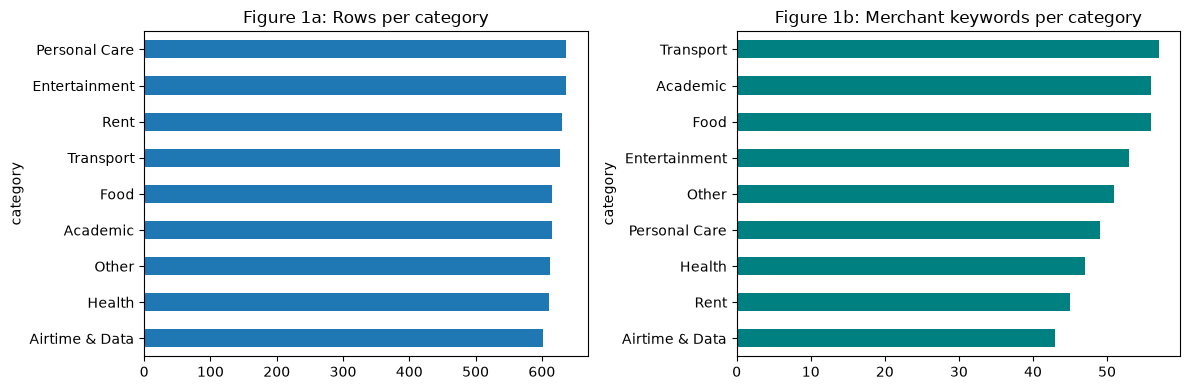

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_category["rows"].sort_values().plot.barh(ax=axes[0], title="Figure 1a: Rows per category")
per_category["keywords"].sort_values().plot.barh(ax=axes[1], color="teal",
                                                 title="Figure 1b: Merchant keywords per category")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

words_per_description = df["description"].str.split().str.len()
print("Words per description: mean", round(words_per_description.mean(), 2),
      "| median", words_per_description.median(), "| longest", words_per_description.max())

single_words = CountVectorizer(lowercase=False, token_pattern=r"\S+").fit(df["doc"])
words_and_pairs = CountVectorizer(**vectorizer_kwargs()).fit(df["doc"])
print("Different single words:", len(single_words.vocabulary_))
print("Features (single words + word pairs):", len(words_and_pairs.vocabulary_), "for", len(df), "rows")

Words per description: mean 3.53 | median 4.0 | longest 8
Different single words: 510
Features (single words + word pairs): 5354 for 5587 rows


### Observations

1. **The categories are represented in similar numbers.** Each has about 11% of the rows (Figure 1a), ranging from 602 to 637 records. This is the distribution in the Kaggle dataset; actual student spending may differ.
2. **The number of merchants per category is uneven.** It ranges from 43 keywords (Airtime & Data) to 57 (Transport) (Figure 1b). A category with fewer merchants has fewer examples of merchant names, which may make it harder to classify merchants not represented in the dataset.
3. **The amount helps mainly at the extremes.** Only Academic and Rent have payments of KES 10,000 or more, and Airtime & Data has the smallest amounts (amount table in Section 1). In the middle range most categories overlap.
4. **Descriptions are short.** They average 3.53 words, so the merchant name is usually the only strong clue.
5. **Template words carry no category signal.** No template word puts more than 0.132 of its rows in one category (Step 2), so the model cannot score well just by learning the templates.
6. **There are about as many features as rows.** 5,354 features for 5,587 rows is a setting where complex models tend to overfit, which is one reason to start with a simple model.


# 4. Model training and validation

**Approach.** Every row has a known category, so this is supervised learning, and the target is one of nine labels, so it is multi-class classification. Clustering does not apply because the labels already exist, and regression does not apply because the target is not a number.

**Base model.** We use Multinomial Naive Bayes. It is designed for word counts, trains quickly and is easy to interpret. We compare it with five other algorithms from the course: Logistic Regression, Decision Tree, K-Nearest Neighbours, Random Forest and Gradient Boosting.

**Validation.** We use 5-fold stratified cross-validation. The data is split into five parts with the same mix of categories; each model is trained on four parts and tested on the fifth, five times, and the scores are averaged. Every model uses the same five parts. The metric is accuracy, which is fair here because the classes are balanced (random guessing would score 1/9, about 0.111).

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, cross_validate
from sklearn.metrics import precision_score, recall_score

X = df["doc"]          # model input: cleaned text + price band
y = df["category"]     # label
CLASSES = sorted(y.unique())

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # the same 5 folds for every model

def make_pipeline(model):
    # Turn each document into counts of its words and word pairs, then apply the model
    return Pipeline([("counts", CountVectorizer(**vectorizer_kwargs())), ("model", model)])

base_model = make_pipeline(MultinomialNB())
scores = cross_val_score(base_model, X, y, cv=folds, scoring="accuracy")

print("Accuracy per fold:", scores.round(4))
print("Mean accuracy:", round(scores.mean(), 4), "+/-", round(scores.std(), 4))
print("Random guessing:", round(1 / len(CLASSES), 4))

Accuracy per fold: [0.9776 0.9741 0.9696 0.9731 0.9785]
Mean accuracy: 0.9746 +/- 0.0032
Random guessing: 0.1111


**Limitation.** The 5,587 rows include only 457 distinct merchant keywords, so the same merchant may appear in both the training and test folds. The model may partly recognize merchants it has already seen, which can make the score optimistic for merchants not represented in the dataset.

## Precision and recall

Precision: of the rows predicted as a category, how many really belong to it. Recall: of the rows that belong to a category, how many the model found. Each row is predicted by the fold model that did not see it during training.

In [16]:
predictions = cross_val_predict(base_model, X, y, cv=folds)

per_class = pd.DataFrame({
    "precision": precision_score(y, predictions, labels=CLASSES, average=None),
    "recall": recall_score(y, predictions, labels=CLASSES, average=None),
}, index=CLASSES).round(4)

print("Misclassified rows:", (predictions != y).sum(), "of", len(y))
per_class

Misclassified rows: 142 of 5587


,precision,recall
Academic,0.9983,0.9302
Airtime & Data,0.9625,0.9817
Entertainment,0.9517,0.9906
Food,0.9916,0.9627
Health,0.9711,0.9902
Other,0.9866,0.9657
Personal Care,0.9678,0.9922
Rent,0.9627,0.9841
Transport,0.9839,0.9729


142 of the 5,587 rows are misclassified. Academic has the lowest recall (0.9302), because its amounts range from KES 20 (printing) to about KES 60,000 (fees) and overlap with every other category. Entertainment has the lowest precision (0.9517).

## Comparing with other models

Five other algorithms go through the same pipeline and the same folds, so any difference comes from the algorithm. We also record the accuracy on the training folds: a much higher training score than test score means overfitting, and low scores on both mean underfitting.

In [17]:
models = {
    "Naive Bayes (base)": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbours": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    # return_train_score=True also scores each model on its own training folds
    cv = cross_validate(make_pipeline(model), X, y, cv=folds, scoring="accuracy",
                        return_train_score=True, n_jobs=-1)   # n_jobs=-1 uses all CPU cores
    results.append({"model": name,
                    "test_accuracy": cv["test_score"].mean(),
                    "train_accuracy": cv["train_score"].mean()})

results = pd.DataFrame(results).sort_values("test_accuracy", ascending=False).round(4)
results

,model,test_accuracy,train_accuracy
1,Logistic Regression,0.9998,1.0000
5,Gradient Boosting,0.9993,0.9996
0,Naive Bayes (base),0.9746,0.9968
4,Random Forest,0.9535,1.0000
2,Decision Tree,0.9042,1.0000
3,K-Nearest Neighbours,0.2705,0.5521


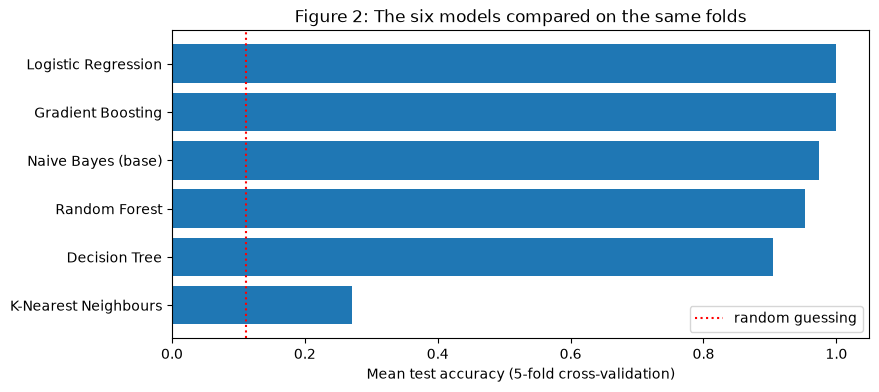

In [18]:
plt.figure(figsize=(9, 4))
plt.barh(results["model"], results["test_accuracy"])
plt.axvline(1 / len(CLASSES), color="red", linestyle=":", label="random guessing")
plt.xlabel("Mean test accuracy (5-fold cross-validation)")
plt.title("Figure 2: The six models compared on the same folds")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

### Why the other models were not chosen

- **Logistic Regression and Gradient Boosting** score slightly higher than Naive Bayes, but their near-perfect scores come from the repeated-merchant effect described above: the same merchants appear in the training and test folds, so a model that memorises merchants scores close to 1.0. This comparison cannot fairly separate them from Naive Bayes, so we keep the simpler Naive Bayes model until the comparison is repeated with a validation split that holds out merchants not seen during training.
- **Random Forest** averages many trees and overfits less than a single tree, but it still scores below Naive Bayes (about 0.95).
- **Decision Tree** overfits: it is perfect on its training folds but scores about 0.90 on the test folds.
- **K-Nearest Neighbours** underfits, scoring only about a quarter on the test folds. It labels a row using its most similar rows, and with word counts the most similar rows usually share the same template ("merchant payment to ...") rather than the same merchant.